<a href="https://colab.research.google.com/github/srigstinahf/Proyek_SpecialSkill01/blob/main/Prediksi_Penjualan_dari_Anggaran_Iklan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Camp 01 — Prediksi Penjualan dari Anggaran Iklan

| | |
|---|---|
| **Dataset** | Advertising Dataset (TV, Radio, Newspaper → Sales) |
| **Algoritma** | Linear Regression |
| **Tujuan** | Memprediksi jumlah penjualan berdasarkan anggaran iklan |

---

**Konteks Bisnis:**  
Sebuah perusahaan mengalokasikan anggaran iklan ke tiga media: TV, Radio, dan Koran.  
Yang ingin dicari tahu → *seberapa besar anggaran iklan mempengaruhi penjualan?*  
Dengan model ini, perusahaan bisa **memprediksi penjualan** sebelum benar-benar mengeluarkan biaya iklan.

### Alur Kerja
```
Load Data → Lihat Data → Visualisasi → Train Model → Evaluasi → Prediksi
```

---
## 1. Import Library

In [ ]:
# Mengimpor semua library yang dibutuhkan

import pandas as pd                              # Untuk membaca dan mengelola data
import numpy as np                               # Untuk operasi matematika
import matplotlib.pyplot as plt                  # Untuk membuat grafik
import seaborn as sns                            # Untuk grafik yang lebih menarik

from sklearn.model_selection import train_test_split   # Membagi data latih dan uji
from sklearn.linear_model import LinearRegression      # Algoritma Linear Regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Metrik evaluasi

print('✅ Library berhasil diimpor!')

✅ Library berhasil diimpor!


---
## 2. Load Dataset

Dataset berisi **200 baris** data iklan perusahaan dengan 4 kolom:
- `TV` — anggaran iklan di TV (dalam ribuan dolar)
- `Radio` — anggaran iklan di Radio
- `Newspaper` — anggaran iklan di Koran
- `Sales` — hasil penjualan (dalam ribuan unit) >>> **ini yang ingin diprediksi**

In [ ]:
# URL dataset yang bisa diakses langsung tanpa perlu login
url = 'https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv'

# Membaca file CSV dari internet ke dalam bentuk tabel (DataFrame)
df = pd.read_csv(url, index_col=0)    # index_col=0 → kolom pertama dijadikan index, bukan data

print(f'Ukuran dataset: {df.shape[0]} baris x {df.shape[1]} kolom')
print(f'Kolom : {list(df.columns)}')

# Menampilkan 5 baris pertama
df.head()

Ukuran dataset: 200 baris x 4 kolom
Kolom : ['TV', 'radio', 'newspaper', 'sales']


,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


---
## 3. Melihat Data

In [ ]:
# Menampilkan ringkasan statistik: rata-rata, minimum, maksimum, dll
df.describe().round(2)    # .round(2) agar angka tidak terlalu panjang

,TV,radio,newspaper,sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


In [ ]:
# Mengecek apakah ada data yang kosong (missing value)
print('Jumlah nilai kosong per kolom:')
print(df.isnull().sum())    # .isnull() → True jika kosong, .sum() → total per kolom

# Mengecek apakah ada baris yang duplikat
print(f'\nJumlah baris duplikat: {df.duplicated().sum()}')

print('\n✅ Data bersih, tidak ada missing value maupun duplikat!')

Jumlah nilai kosong per kolom:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Jumlah baris duplikat: 0

✅ Data bersih, tidak ada missing value maupun duplikat!


---
## 4. Visualisasi Data

Sebelum membuat model, lihat dulu hubungan antar kolom secara visual.

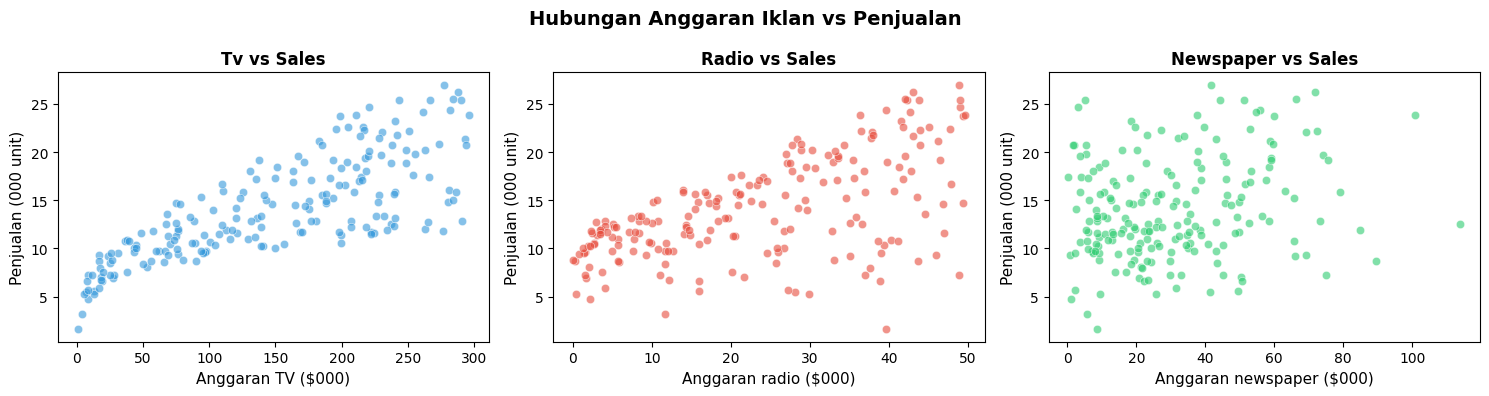

📌 Observasi:
  - TV memiliki hubungan PALING KUAT dengan penjualan (titik membentuk pola naik)
  - Radio juga berpengaruh cukup signifikan
  - Newspaper paling lemah pengaruhnya


In [ ]:
# Membuat 3 grafik scatter plot berdampingan
# Scatter plot digunakan untuk melihat hubungan antara dua variabel numerik

fig, axes = plt.subplots(1, 3, figsize=(15, 4))    # 1 baris, 3 kolom grafik
fig.suptitle('Hubungan Anggaran Iklan vs Penjualan', fontsize=14, fontweight='bold')

media = ['TV', 'radio', 'newspaper']        # Daftar jenis media iklan (corrected casing)
warna = ['#3498db', '#e74c3c', '#2ecc71']   # Warna berbeda untuk setiap grafik

for i, (kolom, wrn) in enumerate(zip(media, warna)):   # Iterasi setiap media
    axes[i].scatter(
        df[kolom],     # Sumbu X: anggaran iklan
        df['sales'],   # Sumbu Y: hasil penjualan
        color=wrn,
        alpha=0.6,     # Transparansi titik (0=transparan, 1=solid)
        edgecolors='white', linewidth=0.5
    )
    axes[i].set_xlabel(f'Anggaran {kolom} ($000)', fontsize=11)
    axes[i].set_ylabel('Penjualan (000 unit)', fontsize=11)
    axes[i].set_title(f'{kolom.capitalize()} vs Sales', fontsize=12, fontweight='bold') # Capitalize for display

plt.tight_layout()    # Merapikan jarak antar grafik
plt.show()

print('📌 Observasi:')
print('  - TV memiliki hubungan PALING KUAT dengan penjualan (titik membentuk pola naik)')
print('  - Radio juga berpengaruh cukup signifikan')
print('  - Newspaper paling lemah pengaruhnya')

---
## 5. Membuat & Melatih Model Linear Regression

**Linear Regression** bekerja dengan mencari garis lurus terbaik yang melewati data.

Rumusnya: `Sales = a₀ + a₁(TV) + a₂(Radio) + a₃(Newspaper)`

Model akan 'belajar' nilai `a₀, a₁, a₂, a₃` dari data latih.

In [ ]:
# ── Pisahkan Fitur (X) dan Target (y) ──────────────────────────────────
X = df[['TV', 'radio', 'newspaper']]   # Fitur: 3 kolom anggaran iklan
y = df['sales']                         # Target: kolom penjualan yang ingin diprediksi

print(f'Fitur X  : {list(X.columns)}')
print(f'Target y : Sales')

# ── Bagi Data: 80% Latih, 20% Uji ──────────────────────────────────────
# Data latih dipakai model untuk BELAJAR
# Data uji dipakai untuk MENGETES apakah model sudah bagus
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,     # 20% untuk data uji
    random_state=42    # Agar hasil pembagian selalu sama setiap dijalankan
)

print(f'\nData latih : {len(X_train)} baris')
print(f'Data uji   : {len(X_test)} baris')

# ── Buat dan Latih Model ────────────────────────────────────────────────
model = LinearRegression()         # Membuat objek model Linear Regression
model.fit(X_train, y_train)        # Melatih model dengan data latih
                                   # .fit() = proses belajar model

print('\n✅ Model selesai dilatih!')
print('\nBobot (koefisien) yang dipelajari model:')
for nama, koef in zip(X.columns, model.coef_):   # model.coef_ = nilai a₁, a₂, a₃
    print(f'  {nama:<12}: {koef:.4f}')
print(f'  Intercept   : {model.intercept_:.4f}')  # model.intercept_ = nilai a₀

Fitur X  : ['TV', 'radio', 'newspaper']
Target y : Sales

Data latih : 160 baris
Data uji   : 40 baris

✅ Model selesai dilatih!

Bobot (koefisien) yang dipelajari model:
  TV          : 0.0447
  radio       : 0.1892
  newspaper   : 0.0028
  Intercept   : 2.9791


---
## 6. Evaluasi Model

| Metrik | Artinya |
|---|---|
| **MAE** | Rata-rata selisih prediksi vs nilai asli (dalam satuan data) |
| **RMSE** | Seperti MAE, tapi lebih sensitif terhadap kesalahan besar |
| **R² Score** | Seberapa baik model menjelaskan data (0–1, semakin tinggi semakin baik) |

In [ ]:
# Menggunakan model untuk membuat prediksi pada data uji
y_pred = model.predict(X_test)    # .predict() = menghasilkan prediksi berdasarkan fitur

# Menghitung metrik evaluasi
mae  = mean_absolute_error(y_test, y_pred)                    # MAE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))            # RMSE = akar dari MSE
r2   = r2_score(y_test, y_pred)                               # R² Score

print('=' * 45)
print('       HASIL EVALUASI MODEL')
print('=' * 45)
print(f'  MAE       : {mae:.2f}  (ribuan unit)')
print(f'  RMSE      : {rmse:.2f}  (ribuan unit)')
print(f'  R² Score  : {r2:.4f}  ({r2*100:.1f}%)')
print('=' * 45)
print(f'\n✅ Interpretasi R²:')
print(f'   Model mampu menjelaskan {r2*100:.1f}% variasi penjualan')
print(f'   hanya dari data anggaran iklan.')

# Membandingkan 5 prediksi vs nilai asli
print('\nContoh Perbandingan Prediksi vs Aktual:')
hasil = pd.DataFrame({'Aktual': y_test.values[:5], 'Prediksi': y_pred[:5].round(2)})
hasil['Selisih'] = (hasil['Prediksi'] - hasil['Aktual']).round(2)
print(hasil.to_string(index=False))

       HASIL EVALUASI MODEL
  MAE       : 1.46  (ribuan unit)
  RMSE      : 1.78  (ribuan unit)
  R² Score  : 0.8994  (89.9%)

✅ Interpretasi R²:
   Model mampu menjelaskan 89.9% variasi penjualan
   hanya dari data anggaran iklan.

Contoh Perbandingan Prediksi vs Aktual:
 Aktual  Prediksi  Selisih
   16.9     16.41    -0.49
   22.4     20.89    -1.51
   21.4     21.55     0.15
    7.3     10.61     3.31
   24.7     22.11    -2.59


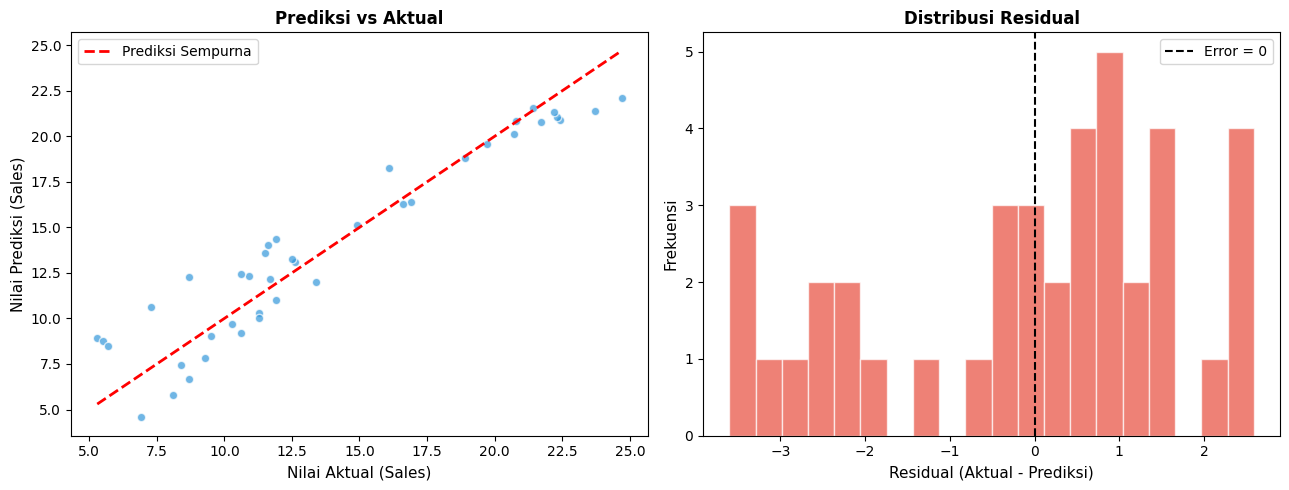

📌 Jika distribusi residual berbentuk lonceng (normal) dan berpusat di 0 → model sudah baik!


In [ ]:
# Grafik perbandingan Prediksi vs Nilai Aktual
# Jika model sempurna → semua titik berada di garis diagonal

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Grafik 1: Scatter Plot Prediksi vs Aktual ──
axes[0].scatter(y_test, y_pred, color='#3498db', alpha=0.7, edgecolors='white')

# Menggambar garis diagonal (garis prediksi sempurna)
batas = [y_test.min(), y_test.max()]         # Batas sumbu
axes[0].plot(batas, batas, 'r--', linewidth=2, label='Prediksi Sempurna')

axes[0].set_xlabel('Nilai Aktual (Sales)', fontsize=11)
axes[0].set_ylabel('Nilai Prediksi (Sales)', fontsize=11)
axes[0].set_title('Prediksi vs Aktual', fontsize=12, fontweight='bold')
axes[0].legend()

# ── Grafik 2: Distribusi Residual (Selisih Error) ──
# Residual = selisih antara prediksi dan nilai asli
# Residual yang baik: tersebar merata di sekitar nol (tidak condong ke satu sisi)
residual = y_test.values - y_pred    # Hitung selisih error
axes[1].hist(residual, bins=20, color='#e74c3c', alpha=0.7, edgecolor='white')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Error = 0')
axes[1].set_xlabel('Residual (Aktual - Prediksi)', fontsize=11)
axes[1].set_ylabel('Frekuensi', fontsize=11)
axes[1].set_title('Distribusi Residual', fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print('📌 Jika distribusi residual berbentuk lonceng (normal) dan berpusat di 0 → model sudah baik!')

---
## 7. Melakukan Prediksi

Sekarang mencoba gunakan model untuk memprediksi penjualan dari anggaran iklan baru.

In [ ]:
# ── Simulasi: Prediksi penjualan dengan anggaran iklan tertentu ──

# Contoh skenario anggaran iklan perusahaan (dalam ribuan dolar)
skenario = [
    {'TV': 200, 'radio': 30, 'newspaper': 10},   # Anggaran besar di TV
    {'TV': 50,  'radio': 60, 'newspaper': 20},   # Fokus ke Radio
    {'TV': 10,  'radio': 10, 'newspaper': 5},    # Anggaran minim
]

df_baru = pd.DataFrame(skenario)    # Ubah list dictionary menjadi DataFrame

# Menggunakan model untuk memprediksi penjualan dari data baru
prediksi_baru = model.predict(df_baru)    # .predict() menghasilkan nilai penjualan prediksi

# Menampilkan hasil
df_baru['Prediksi Sales (000 unit)'] = prediksi_baru.round(2)

print('Hasil Prediksi Penjualan:')
print('=' * 55)
print(df_baru.to_string(index=False))
print('=' * 55)
print('\n💡 Satuan: TV/Radio/Newspaper dalam $000, Sales dalam 000 unit')

Hasil Prediksi Penjualan:
 TV  radio  newspaper  Prediksi Sales (000 unit)
200     30         10                      17.63
 50     60         20                      16.62
 10     10          5                       5.33

💡 Satuan: TV/Radio/Newspaper dalam $000, Sales dalam 000 unit


---
## 8. Kesimpulan

Dalam proyek ini telah berhasil melakukan:
1. Memuat dataset iklan nyata dari perusahaan
2. Mengeksplorasi hubungan antara anggaran iklan dan penjualan
3. Melatih model Linear Regression untuk memprediksi penjualan
4. Mengevaluasi performa model dengan MAE, RMSE, dan R²
5. Menggunakan model untuk prediksi skenario baru

### Temuan Utama
- Iklan **TV** memiliki pengaruh terbesar terhadap penjualan
- Model mencapai **R² > 90%** → artinya model cukup baik menjelaskan data
- Perusahaan bisa menggunakan model ini untuk **mengoptimalkan alokasi anggaran iklan**